## Benchmarking with SHAP


<i>


### <i> Imports

In [569]:
# pip install catboost
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from catboost import CatBoostRegressor
from sklearn import metrics

### <i> Loading

In [570]:
# Load the dataframe
df = pd.read_csv("../datasets/diamonds.csv")
df = df.drop("Unnamed: 0", axis=1)
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,922.056984,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,160.082839,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,1104.226246,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,2161.635828,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,54.015950,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,858.606070,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,40.733853,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,1594.534189,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2827.451375,6.15,6.12,3.74


### <i> Numeric Encoding

`cut` `color` `clarity`

In [571]:
# Ordinal mapping cut
category_mapper = {
    'Fair':0,
    'Good':1,
    'Very Good':2,
    'Premium': 3,
    'Ideal': 4
}
df['cut'] = df['cut'].map(category_mapper)

# Ordinal mapping color
category_mapper = {
    "D": 0,
    "E": 1,
    "F": 2,
    "G": 3,
    "H": 4,
    "I": 5,
    "J": 6
}
df["color"] = df["color"].map(category_mapper)

category_mapper = {
    "IF": 0,
    "VVS1": 1,
    "VVS2": 2,
    "VS1": 3,
    "VS2": 4,
    "SI1": 5,
    "SI2": 6,
    "I1": 7
}
df["clarity"] = df["clarity"].map(category_mapper)

df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4,1,6,61.5,55.0,922.056984,3.95,3.98,2.43
1,0.21,3,1,5,59.8,61.0,160.082839,3.89,3.84,2.31
2,0.23,1,1,3,56.9,65.0,1104.226246,4.05,4.07,2.31
3,0.29,3,5,4,62.4,58.0,2161.635828,4.20,4.23,2.63
4,0.31,1,6,6,63.3,58.0,54.015950,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,4,0,5,60.8,57.0,858.606070,5.75,5.76,3.50
53936,0.72,1,0,5,63.1,55.0,40.733853,5.69,5.75,3.61
53937,0.70,2,0,5,62.8,60.0,1594.534189,5.66,5.68,3.56
53938,0.86,3,4,6,61.0,58.0,2827.451375,6.15,6.12,3.74


--- 

### <i> Function Creation

We're going to train the model, get the metrics, and retrieve the Shapley values using a  function.

Otherwise, we're going to overwhelm the entire notebook with the same 30 lines of code while making changes.

This approach also puts each training session's useful information in a list, which we can turn into a pandas dataframe.

In [572]:
benchmark = []

def get_model_dict(df, target, message):

    # X, y -- Test, train split
    X = df.drop(columns=[target])
    y = df[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = CatBoostRegressor(
        iterations=5,
        loss_function="RMSE",
        verbose=0,
        random_seed=42
    )
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)
    print("Model trained and y_pred predicted")

    # Metrics recording
    mae = metrics.mean_absolute_error(y_test, y_pred)
    mse = metrics.mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
    r_sq = metrics.r2_score(y_test, y_pred)
    print("Metrics generated")

    # Generate SHAP values
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(X_test)
    print("Shap values created")

    # Create a dataframe with actual and predicted values.
    predictions_df = X_test
    predictions_df["Actual"] = y_test.values
    predictions_df["Predicted"] = y_pred
    predictions_df["Residual"] = y_test.values - y_pred

    # Creating a dictionary with the model, metrics, shap values.
    model_dict = {
        "model": model,
        "shap": shap_values,
        "mae": mae,
        "mse": mse,
        "rmse": rmse,
        "r_sq": r_sq,
        "pred_df": predictions_df,
        "message": message,
        "X_test": X_test,
        "Residual": y_test.values - y_pred,

    }

    # Printing metrics
    print("--------------------------")
    print("METRICS")
    print("--------------------------")
    print("MAE")
    print(f"{round(mae,2)} \n")
    print("MSE")
    print(f"{round(mse,2)} \n")
    print("RMSE")
    print(f"{round(rmse,2)} \n")
    print('R-squared:')
    print(f"{round(r_sq,2)} \n")

    return model_dict


---

## <i> Benchmarking

### <i> Change 0

Let's start with a baseline. 

In [573]:
# Train, get metrics, get shap values.
model_dict = get_model_dict(df, "price", "Baseline")


# Add the dictionary to our list. 
benchmark.append(model_dict)

# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)


Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
1057.62 

MSE
1821041.38 

RMSE
1349.46 

R-squared:
0.89 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.46,0.891,Baseline


<i> R-squared seems like a reasonable fit, but the MAE is sort of high. 

### <i> Beeswarm

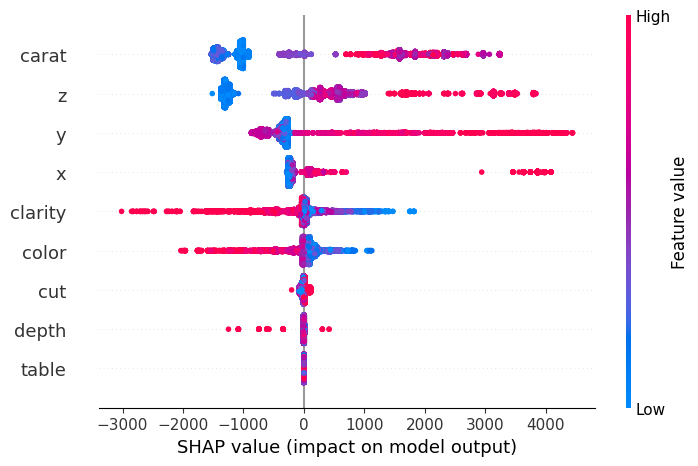

In [574]:
# We use the benchmark list like so,
# [0] = 1st trained model
# ["shap"] = The shapley values of that model.
shap_values = benchmark[0]["shap"]

# Recreating the beeswarm plot
shap.plots.beeswarm(shap_values)

<i> The `carat` feature is considered the most important to `XGBoost` here. Judging by the importance values, I am suspecting distribution issues and a desparate need for scaling.

### <i> Checking out the worst residual error

Let's also inspect the problems with the worst predicted errors.

In [575]:
predictions_df = benchmark[0]["pred_df"]
predictions_df.sort_values("Residual", ascending=False).round(4)

,carat,cut,color,clarity,depth,table,x,y,z,Actual,Predicted,Residual
26407,1.00,1,0,0,63.3,59.0,6.33,6.37,4.02,16430.5920,8464.2533,7966.3387
21935,1.01,0,0,6,64.6,58.0,6.25,6.20,4.02,11191.7123,4438.6912,6753.0211
27580,1.60,4,2,4,62.0,55.0,7.49,7.54,4.66,20184.9373,13504.6926,6680.2447
26491,1.01,2,0,0,61.6,56.0,6.43,6.46,3.97,15333.0393,8903.6896,6429.3498
26237,1.04,3,0,0,60.6,56.0,6.60,6.54,3.98,15000.6635,8903.6896,6096.9739
...,...,...,...,...,...,...,...,...,...,...,...,...
13118,2.15,0,6,7,65.5,57.0,8.01,7.95,5.23,3444.5875,9014.8560,-5570.2685
22710,2.06,4,5,6,61.4,57.0,8.22,8.18,5.03,8461.6570,14072.2915,-5610.6346
16298,2.00,1,6,7,63.6,62.0,7.97,7.80,5.02,4600.7729,10724.5645,-6123.7917
22494,2.00,3,5,6,62.3,57.0,8.12,8.05,5.03,6141.8962,12881.1242,-6739.2280


### <i> Waterfall

Let's make a waterfall of the worst prediction.

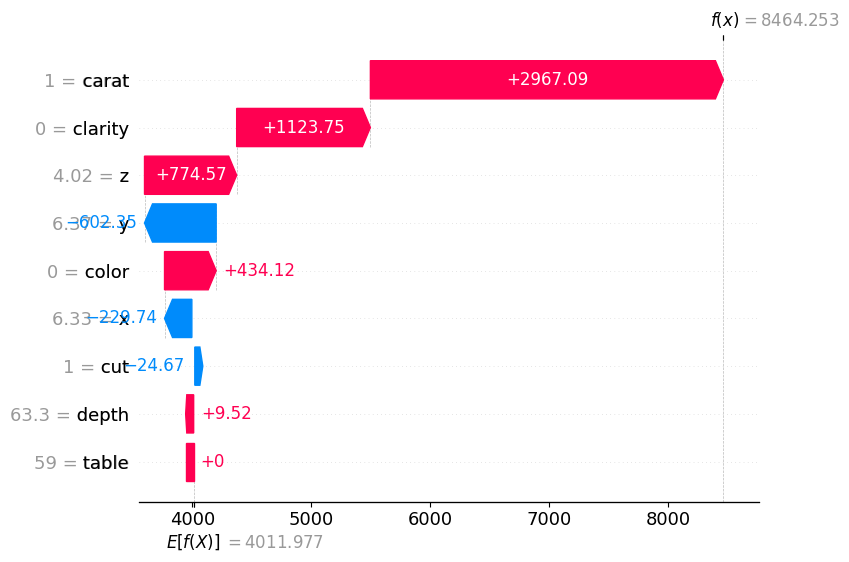

In [576]:

# Get the index of the row with the largest residual.
row_index = predictions_df["Residual"].idxmax()

# Find its position in the SHAP array.
shap_index = predictions_df.index.get_loc(row_index)

# Plot its SHAP explanation.
shap.plots.waterfall(benchmark[0]["shap"][shap_index])

<i> Looks like carat played the biggest role in determining deciding the `price` for this row. 

### Histplots

<i> Let's now look at the distributions. I fear they probably play a role with these issues.

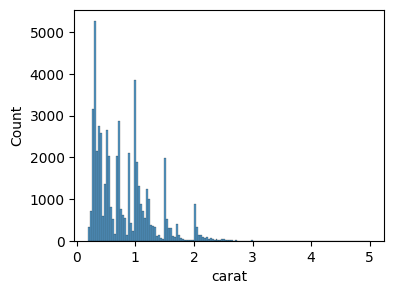

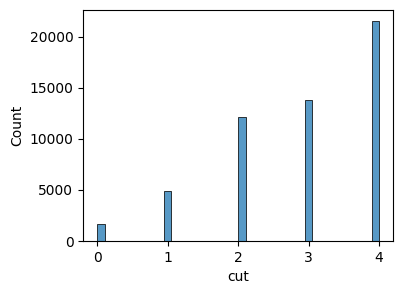

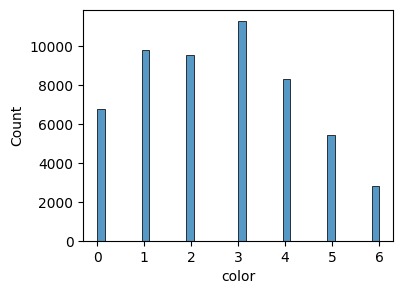

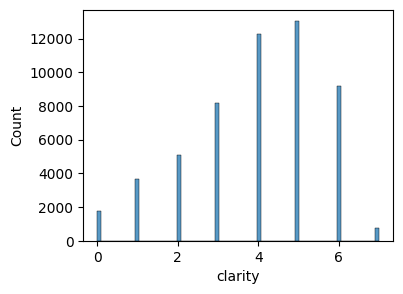

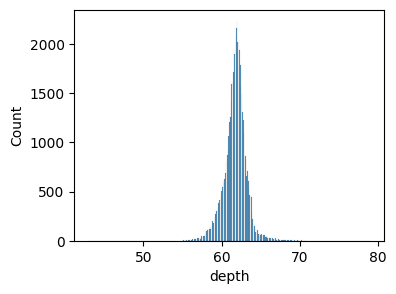

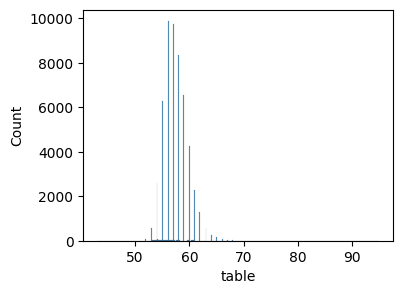

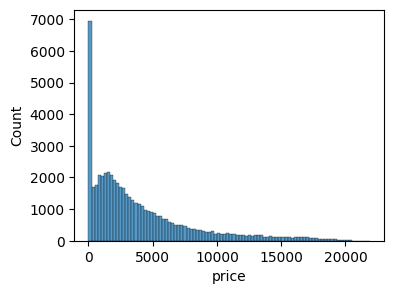

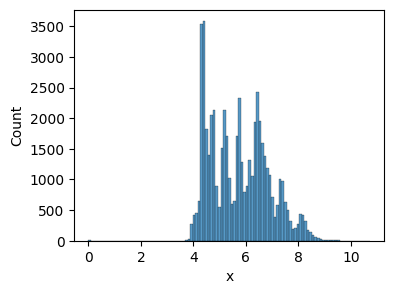

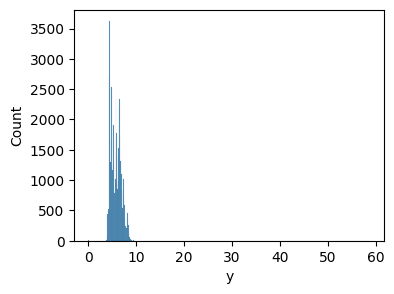

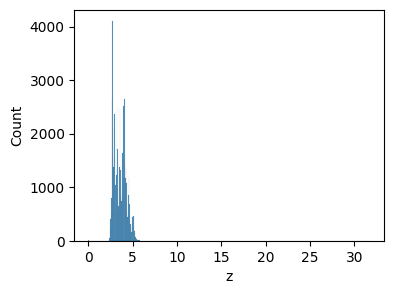

In [577]:
for column in df.columns:
    plt.figure(figsize=(4,3))
    sns.histplot(df, x=column)
    plt.show()

<i> 
Ok! We have distribution problems. Outliers, under-representation, and right-skewed, leptokurtic distributions. 

<br>

Notice how `carat` and `x` have polymodal distributions(up and down, up and down). That could be noise, but let's rule out under-representation first.

---

## <i> Change 1 -- Target feature transformation

`Yeo-Johnson`

In [578]:
from sklearn.preprocessing import PowerTransformer

yeo_df = df.copy()

pt = PowerTransformer(method='yeo-johnson')
yeo_df['price'] = pt.fit_transform(yeo_df[['price']])

# Train, get metrics, get shap values.
model_dict = get_model_dict(yeo_df, "price", "Target yeo-johnson transformation")

# Add the dictionary to our list. 
benchmark.append(model_dict)

# Add the dictionary to our list. 
# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)

Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
0.4 

MSE
0.28 

RMSE
0.53 

R-squared:
0.72 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.46,0.891,Baseline
1,0.398,0.281,0.53,0.720,Target yeo-johnson transformation


`boxcox`

In [579]:
from scipy import stats

boxcox_df = df.copy()
boxcox_df['price'], _ = stats.boxcox(boxcox_df['price'] + 1)  # +1 if zeros exist

# Train, get metrics, get shap values.
model_dict = get_model_dict(boxcox_df, "price", "Target boxcox transformation")

# Add the dictionary to our list. 
benchmark.append(model_dict)

# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)

Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
8.11 

MSE
116.59 

RMSE
10.8 

R-squared:
0.72 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.460,0.891,Baseline
1,0.398,0.281,0.530,0.720,Target yeo-johnson transformation
2,8.112,116.588,10.798,0.720,Target boxcox transformation


### <i> Standings

`r_sq` is not really indicating a fit from transformations here. Not a good result.

`mae`,`mse`,`rmse` all go down, but that's because we scaled down the target values -- So that doesn't count.

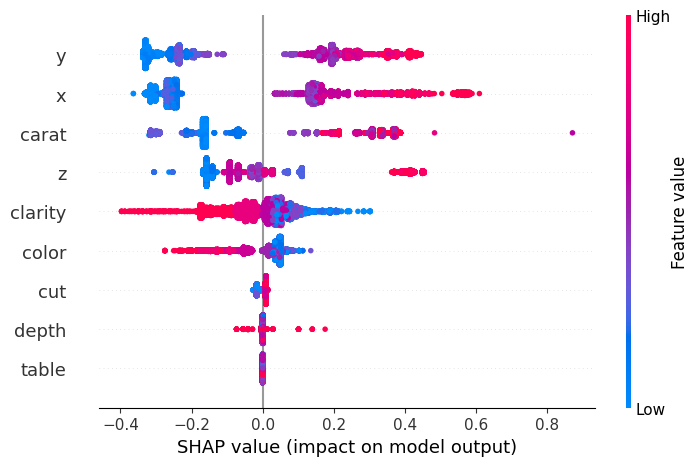

In [580]:
# We can see just how much it messed up the importance of the model in the SHAP plot.
shap_values = benchmark[1]["shap"]
shap.plots.beeswarm(shap_values)

<i>

`table` `depth` and `cut` are mostly flat. That might suggest that they are not useful in the model. Let's consider dropping them.

---

## <i> Change 2 -- Dropping `depth`, `table` columns

In [581]:
df_drop = df.drop(["table", "depth"], axis=1)

# Train, get metrics, get shap values.
model_dict = get_model_dict(df_drop, "price", "Dropped `depth`, `table` column")

# Add the dictionary to our list. 
benchmark.append(model_dict)

# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)


Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
1060.55 

MSE
1858497.26 

RMSE
1363.27 

R-squared:
0.89 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.460,0.891,Baseline
1,0.398,0.281,0.530,0.720,Target yeo-johnson transformation
2,8.112,116.588,10.798,0.720,Target boxcox transformation
3,1060.545,1858497.264,1363.267,0.888,"Dropped `depth`, `table` column"


In [582]:
df_drop = df.drop(["depth"], axis=1)

# Train, get metrics, get shap values.
model_dict = get_model_dict(df_drop, "price", "Dropped `depth` column")

# Add the dictionary to our list. 
benchmark.append(model_dict)

# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)

Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
1056.37 

MSE
1831522.9 

RMSE
1353.34 

R-squared:
0.89 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.460,0.891,Baseline
1,0.398,0.281,0.530,0.720,Target yeo-johnson transformation
2,8.112,116.588,10.798,0.720,Target boxcox transformation
3,1060.545,1858497.264,1363.267,0.888,"Dropped `depth`, `table` column"
4,1056.366,1831522.895,1353.338,0.890,Dropped `depth` column


In [583]:
df_drop = df.drop("table", axis=1)

# Train, get metrics, get shap values.
model_dict = get_model_dict(df_drop, "price", "Dropped `table` column")

# Add the dictionary to our list. 
benchmark.append(model_dict)

# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)

Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
1056.37 

MSE
1831522.9 

RMSE
1353.34 

R-squared:
0.89 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.460,0.891,Baseline
1,0.398,0.281,0.530,0.720,Target yeo-johnson transformation
2,8.112,116.588,10.798,0.720,Target boxcox transformation
3,1060.545,1858497.264,1363.267,0.888,"Dropped `depth`, `table` column"
4,1056.366,1831522.895,1353.338,0.890,Dropped `depth` column
5,1056.366,1831522.895,1353.338,0.890,Dropped `table` column


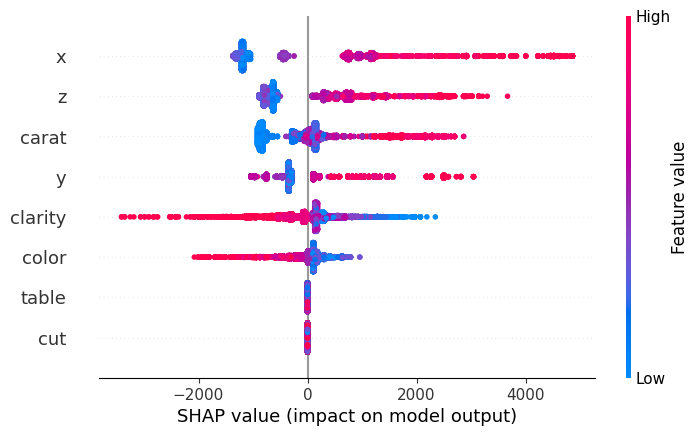

In [584]:
# We can see just how much it messed up the importance of the model in the SHAP plot.
shap_values = benchmark[4]["shap"]
shap.plots.beeswarm(shap_values)

<i> 

So dropping `table`, `depth` them weren't necessarily useful! I am now HEAVILY suspecting noise to be an issue.



---

### SavGol can't be used, this introduces target leakage

## <i> Change 3 -- Savitz-Golay Column Transformation

Since I suspect noise now, let's experiment with Savgol, a noise transformer.

`window = 50`

In [585]:
from scipy.signal import savgol_filter

# Create a new dataset
df_savgol = df

# Set a window length
window_len = 50

# Apply Savitzky-Golay filter
df_savgol["price_smoothed"] = savgol_filter(
    df_savgol["price"],
    window_length=window_len,
    polyorder=3
)

df_savgol = df_savgol.drop("price", axis=1)

# Train, get metrics, get shap values.
model_dict = get_model_dict(df_savgol, "price_smoothed", f"target savgol transform, window={window_len}")

# Add the dictionary to our list. 
benchmark.append(model_dict)

# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)

Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
621.82 

MSE
979602.34 

RMSE
989.75 

R-squared:
0.93 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.460,0.891,Baseline
1,0.398,0.281,0.530,0.720,Target yeo-johnson transformation
2,8.112,116.588,10.798,0.720,Target boxcox transformation
3,1060.545,1858497.264,1363.267,0.888,"Dropped `depth`, `table` column"
4,1056.366,1831522.895,1353.338,0.890,Dropped `depth` column
5,1056.366,1831522.895,1353.338,0.890,Dropped `table` column
6,621.819,979602.341,989.749,0.935,"target savgol transform, window=50"


`window = 18`

In [586]:
from scipy.signal import savgol_filter

# Create a new dataset
df_savgol = df

# Set a window length
window_len = 18

# Apply Savitzky-Golay filter
df_savgol["price_smoothed"] = savgol_filter(
    df_savgol["price"],
    window_length=window_len,
    polyorder=3
)

df_savgol = df_savgol.drop("price", axis=1)

# Train, get metrics, get shap values.
model_dict = get_model_dict(df_savgol, "price_smoothed", f"target savgol transform, window={window_len}")

# Add the dictionary to our list. 
benchmark.append(model_dict)

# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)

Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
632.18 

MSE
907407.32 

RMSE
952.58 

R-squared:
0.94 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.460,0.891,Baseline
1,0.398,0.281,0.530,0.720,Target yeo-johnson transformation
2,8.112,116.588,10.798,0.720,Target boxcox transformation
3,1060.545,1858497.264,1363.267,0.888,"Dropped `depth`, `table` column"
4,1056.366,1831522.895,1353.338,0.890,Dropped `depth` column
5,1056.366,1831522.895,1353.338,0.890,Dropped `table` column
6,621.819,979602.341,989.749,0.935,"target savgol transform, window=50"
7,632.184,907407.319,952.579,0.941,"target savgol transform, window=18"


<i>
Finally, a significant improvement to the dataset. Let's investigate the shap values and histplot

### <i> Histplot

<Axes: xlabel='price', ylabel='Count'>

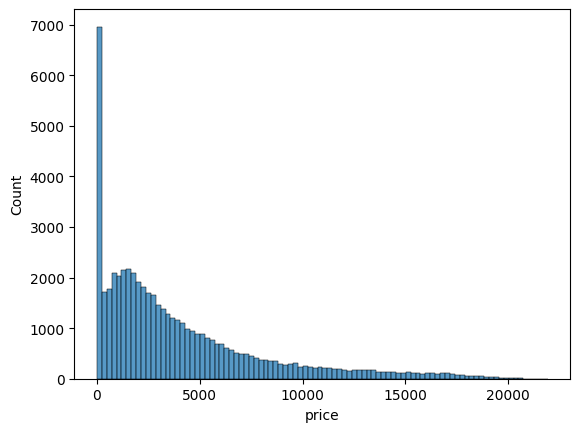

In [587]:
sns.histplot(df, x="price")

<i> We can see that the savgol evens out much better, which is naturally simpler for the model to interpret.

 Still right-skewed, but a LOT less noise and random variation. Great results.

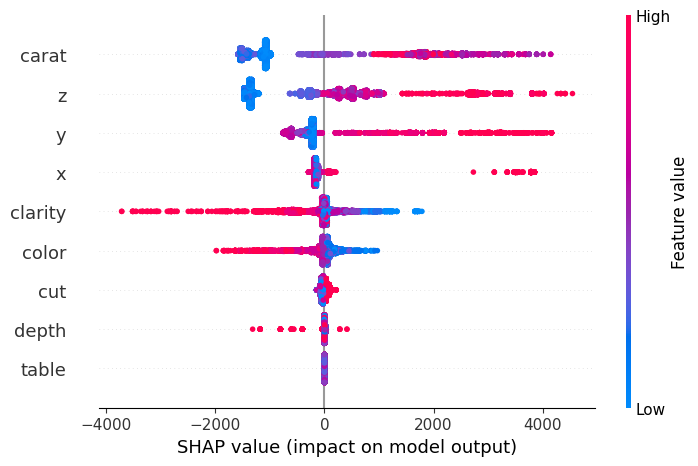

In [588]:
shapley_values = benchmark[7]["shap"]
shap.plots.beeswarm(shapley_values)

<i> We can see the shap values balancing, and the `cut` feature being unpacked. That's a good sign and might be an indication that we need to further de-noisify.

--- 

 ## <i> Change 4 -- PCA

There could still be some noise, we'll see if PCA can handle the rest of the noise in the features.


In [589]:
df_pca

,carat,cut,color,clarity,depth,table,x,y,z,price_smoothed,volume,carat_per_volume
0,0.209448,4.077150,0.663205,5.374157,61.556987,55.074107,4.437606,4.443600,2.729001,-1345.277219,53.813029,0.003892
1,0.161219,3.068559,0.706975,4.448477,59.860424,61.068415,4.341774,4.321158,2.557663,-1339.432354,47.985569,0.003360
2,0.177238,1.049935,0.787743,2.598114,56.957245,65.051359,4.447920,4.447745,2.449938,-297.014966,48.467647,0.003657
3,0.350826,3.075497,4.657597,3.379799,62.448562,58.065613,4.633171,4.614095,2.897182,-509.551174,61.935639,0.005664
4,0.414129,1.090213,5.588670,5.257524,63.353132,58.074123,4.815581,4.805088,3.067471,-1941.076588,70.979105,0.005835
...,...,...,...,...,...,...,...,...,...,...,...,...
53935,0.651398,3.948360,0.237213,5.424818,60.768149,56.957028,5.489679,5.494837,3.329688,2805.486444,100.439679,0.006485
53936,0.660949,0.948608,0.234681,5.420717,63.065527,54.955323,5.435010,5.464203,3.445118,2399.607248,102.313093,0.006460
53937,0.682924,1.959768,0.178300,5.326124,62.770719,59.963023,5.450261,5.423945,3.420634,2855.911135,101.120507,0.006754
53938,0.890157,2.990228,4.038775,6.078506,60.991372,57.989418,6.052658,6.057400,3.689563,2794.375043,135.271827,0.006581


In [590]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select all numeric columns
numeric_columns = df.select_dtypes(include="number").columns

X = df[numeric_columns]

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

# Reconstruct
X_reconstructed = pca.inverse_transform(X_pca)

# Reverse standardization
X_reconstructed = scaler.inverse_transform(X_reconstructed)

# Create a separate DataFrame
df_pca = df.copy()

df_pca[numeric_columns] = pd.DataFrame(
    X_reconstructed,
    columns=numeric_columns,
    index=df.index
)

df_pca = df_pca.drop("price", axis=1)

In [591]:
# Train, get metrics, get shap values.
model_dict = get_model_dict(df_pca, "price_smoothed", "PCA")

# Add the dictionary to our list. 
benchmark.append(model_dict)

# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)

Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
452.51 

MSE
355641.89 

RMSE
596.36 

R-squared:
0.98 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.460,0.891,Baseline
1,0.398,0.281,0.530,0.720,Target yeo-johnson transformation
2,8.112,116.588,10.798,0.720,Target boxcox transformation
3,1060.545,1858497.264,1363.267,0.888,"Dropped `depth`, `table` column"
4,1056.366,1831522.895,1353.338,0.890,Dropped `depth` column
5,1056.366,1831522.895,1353.338,0.890,Dropped `table` column
6,621.819,979602.341,989.749,0.935,"target savgol transform, window=50"
7,632.184,907407.319,952.579,0.941,"target savgol transform, window=18"
8,452.512,355641.891,596.357,0.976,PCA


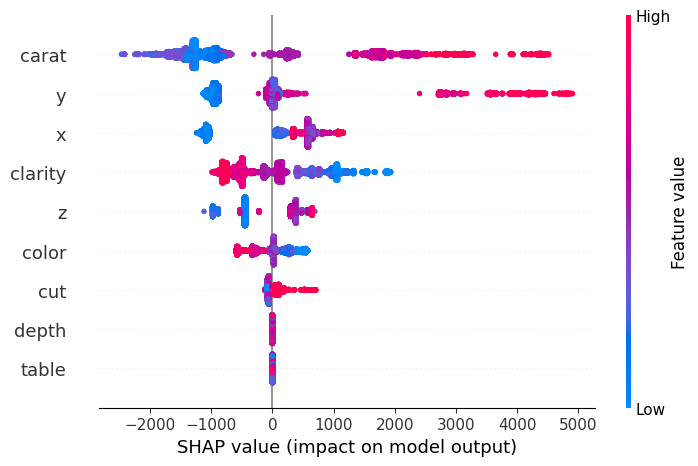

In [592]:
shapley_values = benchmark[8]["shap"]
shap.plots.beeswarm(shapley_values)


 ## <i> Change 5 -- Interaction Features

Now maybe we can try to add some interaction features to the dataset to unlock some potential. 

Let's create a `volume` and `carat_per_volume` interaction features to reveal some more relationships between the features.

In [593]:
df_interfeat = df.copy()

# Some interaction features.
df_pca["volume"] = df_pca["x"] * df_pca["y"] * df_pca["z"]
df_pca["carat_per_volume"] = (df_pca["carat"] / df_pca["volume"].replace(0, np.nan))

# Train, get metrics, get shap values.
model_dict = get_model_dict(df_pca, "price_smoothed", "PCA with interaction features")

# Add the dictionary to our list. 
benchmark.append(model_dict)

# Making a benchmark dataframe
benchmark_df = pd.DataFrame(benchmark)
benchmark_df[["mae", "mse", "rmse", "r_sq", "message"]].round(3)

Model trained and y_pred predicted
Metrics generated
Shap values created
--------------------------
METRICS
--------------------------
MAE
407.25 

MSE
292606.74 

RMSE
540.93 

R-squared:
0.98 



,mae,mse,rmse,r_sq,message
0,1057.617,1821041.381,1349.460,0.891,Baseline
1,0.398,0.281,0.530,0.720,Target yeo-johnson transformation
2,8.112,116.588,10.798,0.720,Target boxcox transformation
3,1060.545,1858497.264,1363.267,0.888,"Dropped `depth`, `table` column"
4,1056.366,1831522.895,1353.338,0.890,Dropped `depth` column
5,1056.366,1831522.895,1353.338,0.890,Dropped `table` column
6,621.819,979602.341,989.749,0.935,"target savgol transform, window=50"
7,632.184,907407.319,952.579,0.941,"target savgol transform, window=18"
8,452.512,355641.891,596.357,0.976,PCA
9,407.247,292606.744,540.931,0.980,PCA with interaction features


---

##  <i>Optimized Product

Alright, let's unpack our more optimized dataset and inspect it!

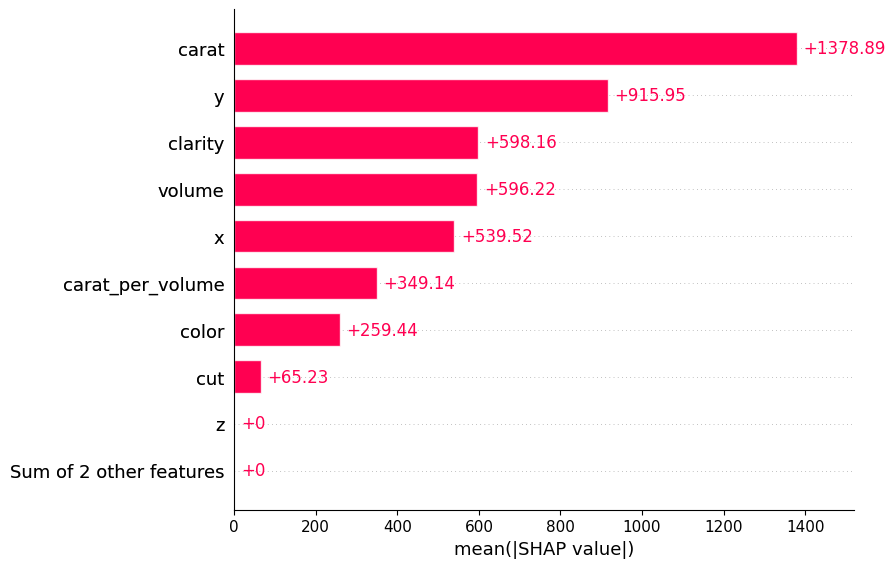

In [594]:
# Here are the final importance values.
shap_values = benchmark[9]["shap"]
shap.plots.bar(shap_values)


<i> Notice how there's few values now that have zero contribution to the dataset. Maybe for next time we can consider dropping those after PCA!

### <i> Scatter vs Error plot.

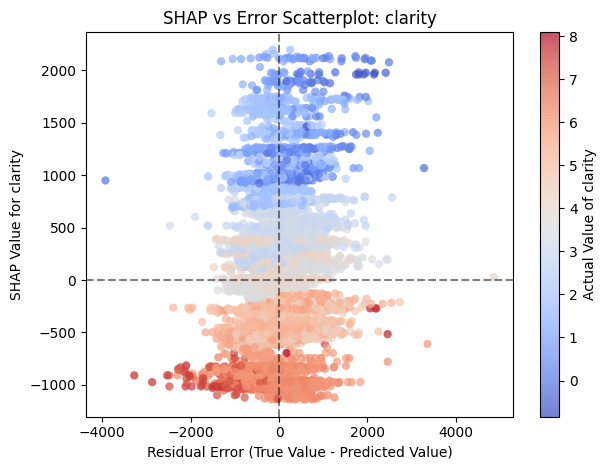

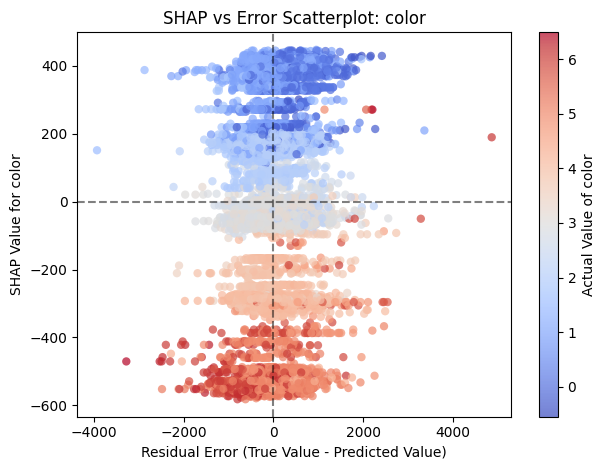

In [595]:
columns = ["clarity", "color"]

X_test = benchmark[9]["X_test"]
residuals = benchmark[9]["Residual"]

for column in columns:

    # Get the feature index
    feature_index = X_test.columns.get_loc(column)

    # Get SHAP values
    feat_shap_values = shap_values.values[:, feature_index]

    # Get raw feature values
    feat_raw_values = X_test[column].values

    # Scatterplot
    sc = plt.scatter(
        residuals,
        feat_shap_values,
        c=feat_raw_values,
        cmap="coolwarm",
        alpha=0.7,
        edgecolors="none"
    )

    plt.axhline(0, color="black", linestyle="--", alpha=0.5)
    plt.axvline(0, color="black", linestyle="--", alpha=0.5)

    plt.title(f"SHAP vs Error Scatterplot: {column}")
    plt.xlabel("Residual Error (True Value - Predicted Value)")
    plt.ylabel(f"SHAP Value for {column}")

    cbar = plt.colorbar(sc)
    cbar.set_label(f"Actual Value of {column}")

    plt.tight_layout()
    plt.show()

<i> There still seems to be some form of outlier errors that could be possibly taken care of by `IsolationForest`. Thoughts for further optimization!

### <i> Checking the worst prediction.

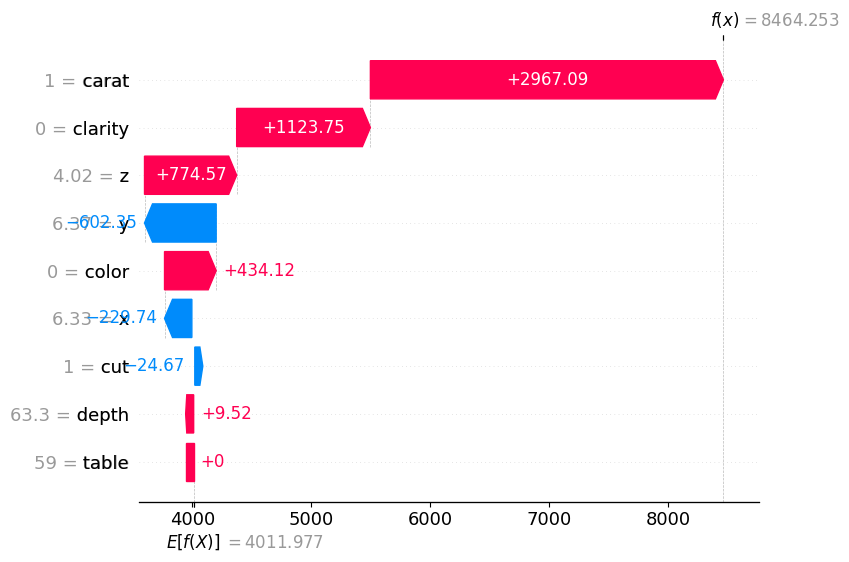

In [596]:
# Get the index of the row with the largest residual.
row_index = predictions_df["Residual"].idxmax()

# Find its position in the SHAP array.
shap_index = predictions_df.index.get_loc(row_index)

# Plot its SHAP explanation.
shap.plots.waterfall(benchmark[0]["shap"][shap_index])

<i> Looks like `carat` still remains to be the strongest predictor with the worst row.

### <i> Dataframe with the 10 worst predictions

In [597]:
worst_preds = predictions_df.sort_values("Residual", ascending=False).head(10)
worst_preds


,carat,cut,color,clarity,depth,table,x,y,z,Actual,Predicted,Residual
26407,1.00,1,0,0,63.3,59.0,6.33,6.37,4.02,16430.592023,8464.253292,7966.338731
21935,1.01,0,0,6,64.6,58.0,6.25,6.20,4.02,11191.712291,4438.691212,6753.021079
27580,1.60,4,2,4,62.0,55.0,7.49,7.54,4.66,20184.937307,13504.692562,6680.244746
26491,1.01,2,0,0,61.6,56.0,6.43,6.46,3.97,15333.039347,8903.689566,6429.349781
26237,1.04,3,0,0,60.6,56.0,6.60,6.54,3.98,15000.663472,8903.689566,6096.973906
26198,1.02,4,0,0,63.0,57.0,6.39,6.35,4.01,15352.986947,9290.147220,6062.839727
26977,2.31,2,5,6,62.9,58.0,8.34,8.43,5.27,19546.549978,13695.701594,5850.848385
27232,1.38,2,2,0,58.2,60.0,7.32,7.39,4.28,18809.192526,12963.216774,5845.975752
27673,1.50,2,3,4,60.7,59.0,7.31,7.38,4.46,17927.463580,12106.542397,5820.921184
27687,1.70,3,3,2,59.8,59.0,7.70,7.75,4.62,20231.007780,14548.810433,5682.197346


<i> What's so different about these compared to the averages?

In [598]:
df.describe()


,carat,cut,color,clarity,depth,table,price,x,y,z,price_smoothed
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,2.904097,2.594197,3.948980,61.749405,57.457184,4005.517868,5.731157,5.734526,3.538734,4005.532049
std,0.474011,1.116600,1.701105,1.647136,1.432621,2.234491,4086.680890,1.121761,1.142135,0.705699,3932.590168
min,0.200000,0.000000,0.000000,0.000000,43.000000,43.000000,1.000000,0.000000,0.000000,0.000000,-1076.951740
25%,0.400000,2.000000,1.000000,3.000000,61.000000,56.000000,1061.362162,4.710000,4.720000,2.910000,1191.861037
50%,0.700000,3.000000,3.000000,4.000000,61.800000,57.000000,2700.335527,5.700000,5.710000,3.530000,2497.104076
75%,1.040000,4.000000,4.000000,5.000000,62.500000,59.000000,5584.065407,6.540000,6.540000,4.040000,5367.887904
max,5.010000,4.000000,6.000000,7.000000,79.000000,95.000000,21934.791381,10.740000,58.900000,31.800000,20299.663647


In [599]:
worst_preds.describe()

,carat,cut,color,clarity,depth,table,x,y,z,Actual,Predicted,Residual
count,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,1.357000,2.300000,1.500000,2.200000,61.670000,57.700000,7.016000,7.041000,4.329000,17000.814525,10681.943462,6318.871064
std,0.433104,1.251666,1.779513,2.573368,1.893292,1.636392,0.714146,0.755814,0.427225,2881.949597,3186.687931,687.685776
min,1.000000,0.000000,0.000000,0.000000,58.200000,55.000000,6.250000,6.200000,3.970000,11191.712291,4438.691212,5682.197346
25%,1.012500,2.000000,0.000000,0.000000,60.625000,56.250000,6.400000,6.392500,4.012500,15338.026247,8903.689566,5847.193910
50%,1.210000,2.000000,1.000000,1.000000,61.800000,58.000000,6.955000,6.960000,4.150000,17179.027802,10698.344808,6079.906817
75%,1.575000,3.000000,2.750000,4.000000,62.975000,59.000000,7.447500,7.502500,4.580000,19362.210615,13369.323615,6617.521004
max,2.310000,4.000000,5.000000,6.000000,64.600000,60.000000,8.340000,8.430000,5.270000,20231.007780,14548.810433,7966.338731
